# Data 200: Data Systems for Data Analytics (Fall 2025)

# Final Project: Macroeconomic Regimes and Apple’s Equity Performance

<font color='red'>**Due Date and Time:** 5:00pm, 19/12/2025 </font>
---

# Name: Grace Ngo

In [3]:
## RUN THIS CELL TO GET THE RIGHT FORMATTING
import os
from datetime import date

import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

# Overview
Financial markets do not operate in isolation from the broader macroeconomic environment. Inflation dynamics, monetary policy, recessions, and real economic growth shape risk premia, discount rates, and investor expectations, which in turn influence asset prices. However, the degree to which macroeconomic conditions determine the long-run performance of individual firms remains contested. This project extends my Project 1 analysis of Apple Inc. (AAPL) by explicitly integrating macroeconomic time series from the Federal Reserve Economic Data (FRED) API. The objective is to assess whether Apple’s equity performance is primarily driven by macroeconomic regimes or by firm-specific fundamentals that dominate over long horizons.

# Exercises

<div class="exercise"><b>Exercise 1:</b></div> Write a function in Python which successfully scrapes or pulls information from the internet/API. 

In [119]:
def get_fred_market_data(api_key, series_id, start_date="1980-01-01", end_date=None, frequency=None, aggregation=None, timeout=30):
    api_key = api_key or os.getenv("FRED_API_KEY") 
    if api_key is None:
        raise ValueError("FRED API key not found. Please set FRED_API_KEY in the environment.")

    if end_date is None:
        end_date = date.today().isoformat()

    url = "https://api.stlouisfed.org/fred/series/observations"

    params = {"api_key": api_key,
              "series_id": series_id,
              "file_type": "json",
              "observation_start": start_date,
              "observation_end": end_date}

    if frequency is not None:
        params["frequency"] = frequency
    if aggregation is not None:
        params["aggregation_method"] = aggregation

    response = requests.get(url, params=params, timeout=timeout)
    response.raise_for_status()

    return pd.DataFrame(response.json()["observations"])

In [122]:
api_key = "c779a7b11de2f2e84745f4f97bbe2feb"

In [125]:
## Extract Inflation CPI data
cpi_raw = get_fred_market_data(api_key, series_id="CPIAUCSL", start_date="1980-01-01")
cpi_raw.head(10)

,realtime_start,realtime_end,date,value
0,2025-12-19,2025-12-19,1980-01-01,78.0
1,2025-12-19,2025-12-19,1980-02-01,79.0
2,2025-12-19,2025-12-19,1980-03-01,80.1
3,2025-12-19,2025-12-19,1980-04-01,80.9
4,2025-12-19,2025-12-19,1980-05-01,81.7
5,2025-12-19,2025-12-19,1980-06-01,82.5
6,2025-12-19,2025-12-19,1980-07-01,82.6
7,2025-12-19,2025-12-19,1980-08-01,83.2
8,2025-12-19,2025-12-19,1980-09-01,83.9
9,2025-12-19,2025-12-19,1980-10-01,84.7


In [126]:
## Extract Recession data
recession_raw = get_fred_market_data(api_key, series_id="USREC", start_date="1980-01-01")
recession_raw.head(10)

,realtime_start,realtime_end,date,value
0,2025-12-19,2025-12-19,1980-01-01,0
1,2025-12-19,2025-12-19,1980-02-01,1
2,2025-12-19,2025-12-19,1980-03-01,1
3,2025-12-19,2025-12-19,1980-04-01,1
4,2025-12-19,2025-12-19,1980-05-01,1
5,2025-12-19,2025-12-19,1980-06-01,1
6,2025-12-19,2025-12-19,1980-07-01,1
7,2025-12-19,2025-12-19,1980-08-01,0
8,2025-12-19,2025-12-19,1980-09-01,0
9,2025-12-19,2025-12-19,1980-10-01,0


In [127]:
## Extract Federal Funds Rate data
rates_raw = get_fred_market_data(api_key, series_id="FEDFUNDS", start_date="1980-01-01")
rates_raw.head(10)

,realtime_start,realtime_end,date,value
0,2025-12-19,2025-12-19,1980-01-01,13.82
1,2025-12-19,2025-12-19,1980-02-01,14.13
2,2025-12-19,2025-12-19,1980-03-01,17.19
3,2025-12-19,2025-12-19,1980-04-01,17.61
4,2025-12-19,2025-12-19,1980-05-01,10.98
5,2025-12-19,2025-12-19,1980-06-01,9.47
6,2025-12-19,2025-12-19,1980-07-01,9.03
7,2025-12-19,2025-12-19,1980-08-01,9.61
8,2025-12-19,2025-12-19,1980-09-01,10.87
9,2025-12-19,2025-12-19,1980-10-01,12.81


In [128]:
## Extract SP500 data
sp500_raw = get_fred_market_data(api_key, series_id="SP500",start_date="2000-01-01")
sp500_raw.head(10)

,realtime_start,realtime_end,date,value
0,2025-12-19,2025-12-19,2015-12-21,2021.15
1,2025-12-19,2025-12-19,2015-12-22,2038.97
2,2025-12-19,2025-12-19,2015-12-23,2064.29
3,2025-12-19,2025-12-19,2015-12-24,2060.99
4,2025-12-19,2025-12-19,2015-12-25,.
5,2025-12-19,2025-12-19,2015-12-28,2056.50
6,2025-12-19,2025-12-19,2015-12-29,2078.36
7,2025-12-19,2025-12-19,2015-12-30,2063.36
8,2025-12-19,2025-12-19,2015-12-31,2043.94
9,2025-12-19,2025-12-19,2016-01-01,.


In [129]:
## Extract GDP data
gdp_raw = get_fred_market_data(api_key, series_id="GDPC1", start_date="1980-01-01")
gdp_raw.head(10)

,realtime_start,realtime_end,date,value
0,2025-12-19,2025-12-19,1980-01-01,7341.557
1,2025-12-19,2025-12-19,1980-04-01,7190.289
2,2025-12-19,2025-12-19,1980-07-01,7181.743
3,2025-12-19,2025-12-19,1980-10-01,7315.677
4,2025-12-19,2025-12-19,1981-01-01,7459.022
5,2025-12-19,2025-12-19,1981-04-01,7403.745
6,2025-12-19,2025-12-19,1981-07-01,7492.405
7,2025-12-19,2025-12-19,1981-10-01,7410.768
8,2025-12-19,2025-12-19,1982-01-01,7295.631
9,2025-12-19,2025-12-19,1982-04-01,7328.912


<div class="exercise"><b>A brief description of the path and the structure of the API/website. </b></div>

The project retrieves macroeconomic data from the Federal Reserve Economic Data (FRED) API using the endpoint https://api.stlouisfed.org/fred/series/observations. FRED organizes economic indicators as standardized time series, each identified by a unique series_id (e.g., CPIAUCSL for consumer price inflation, USREC for recession indicators, FEDFUNDS for the federal funds rate). This structure allows a single API path to be reused across datasets, with customization handled through query parameters rather than changes to the URL itself.

The custom function exploits this design by holding the endpoint constant and varying parameters such as series_id, observation_start, observation_end, frequency, and aggregation_method. These parameters materially change the data retrieved, allowing the same function to extract inflation, GDP, interest rates, or market indices across different time horizons or temporal resolutions. The function authenticates requests using an API key, validates responses through HTTP status checks, and returns the observations as a Pandas DataFrame. By leveraging FRED’s standardized schema, the function provides a flexible and reproducible mechanism for acquiring macroeconomic data suitable for downstream analysis and visualization.

<div class="exercise"><b>Exercise 2:</b></div>Take the information you have extracted and convert it into a Pandas data frame.

In [130]:
def tidy_fred_data(df, value_name):
    tidy_df = (df.assign(Date = pd.to_datetime(df["date"]), 
                         Value = pd.to_numeric(df["value"], errors = "coerce"))
               [["Date", "Value"]].rename(columns = {"Value": value_name}).dropna().sort_values("Date").reset_index(drop = True))
    return tidy_df

In [131]:
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok = True)

In [132]:
## Converse the Inflation CPI to tidy data
cpi = tidy_fred_data(cpi_raw, value_name = "Inflation_CPI")
cpi.head(10)

,Date,Inflation_CPI
0,1980-01-01,78.0
1,1980-02-01,79.0
2,1980-03-01,80.1
3,1980-04-01,80.9
4,1980-05-01,81.7
5,1980-06-01,82.5
6,1980-07-01,82.6
7,1980-08-01,83.2
8,1980-09-01,83.9
9,1980-10-01,84.7


In [133]:
## Converse the Recession to tidy data
recession = tidy_fred_data(recession_raw, value_name = "Recession")
recession.head(10)

,Date,Recession
0,1980-01-01,0
1,1980-02-01,1
2,1980-03-01,1
3,1980-04-01,1
4,1980-05-01,1
5,1980-06-01,1
6,1980-07-01,1
7,1980-08-01,0
8,1980-09-01,0
9,1980-10-01,0


In [134]:
## Converse the Federal Funds Rate to tidy data
rates = tidy_fred_data(rates_raw, value_name = "Fed_Funds_Rate")
rates.head(10)

,Date,Fed_Funds_Rate
0,1980-01-01,13.82
1,1980-02-01,14.13
2,1980-03-01,17.19
3,1980-04-01,17.61
4,1980-05-01,10.98
5,1980-06-01,9.47
6,1980-07-01,9.03
7,1980-08-01,9.61
8,1980-09-01,10.87
9,1980-10-01,12.81


In [135]:
## Coverse the SP500 to tidy data
sp500 = tidy_fred_data(sp500_raw, value_name = "SP500")
sp500.head(10)

,Date,SP500
0,2015-12-21,2021.15
1,2015-12-22,2038.97
2,2015-12-23,2064.29
3,2015-12-24,2060.99
4,2015-12-28,2056.50
5,2015-12-29,2078.36
6,2015-12-30,2063.36
7,2015-12-31,2043.94
8,2016-01-04,2012.66
9,2016-01-05,2016.71


In [136]:
## Converse the GDP to tidy data
gdp = tidy_fred_data(gdp_raw, value_name = "GDP")
gdp.head(10)

,Date,GDP
0,1980-01-01,7341.557
1,1980-04-01,7190.289
2,1980-07-01,7181.743
3,1980-10-01,7315.677
4,1981-01-01,7459.022
5,1981-04-01,7403.745
6,1981-07-01,7492.405
7,1981-10-01,7410.768
8,1982-01-01,7295.631
9,1982-04-01,7328.912


In [137]:
## Save for submission
cpi.to_csv(os.path.join(DATA_DIR, "fred_cpi.csv"), index=False)
recession.to_csv(os.path.join(DATA_DIR, "fred_recession.csv"), index=False)
rates.to_csv(os.path.join(DATA_DIR, "fred_fedfunds.csv"), index=False)
sp500.to_csv(os.path.join(DATA_DIR, "fred_sp500.csv"), index=False)
gdp.to_csv(os.path.join(DATA_DIR, "fred_gdp.csv"), index=False)

<div class="exercise"><b>Outline transformation and changes needed to make to ensure the newly formed Tabular Data are Tidy</b></div>

Raw FRED data are returned as JSON objects with date and value fields stored as strings. To ensure tidy data principles, each dataset is transformed so that every row represents a single time period, and each column represents a single variable. Dates are converted to proper datetime objects, values are coerced to numeric types with invalid entries removed, and columns are renamed to descriptive variable names. The data are then sorted chronologically and indexed consistently. This process ensures that all macroeconomic series share a common structure and can be merged reliably with each other and with Apple’s stock price data using a unified date key.

<div class="exercise"><b>Exercise 3:</b></div>Create two different visualizations which capture either the relationship between variables in your extracted dataset, a distribution for a single variable which is interesting, or a trend in a variable over time.

<div class="Excercise 3"><b>Inflation Rate with Recession Periods</b></div>

In [138]:
## Inflation rate (year-over-year % change)
cpi_plot = cpi.copy()
cpi_plot["Inflation_YoY"] = cpi_plot["Inflation_CPI"].pct_change(12) * 100

cpi_plot.head(10)

,Date,Inflation_CPI,Inflation_YoY
0,1980-01-01,78.0,NaN
1,1980-02-01,79.0,NaN
2,1980-03-01,80.1,NaN
3,1980-04-01,80.9,NaN
4,1980-05-01,81.7,NaN
5,1980-06-01,82.5,NaN
6,1980-07-01,82.6,NaN
7,1980-08-01,83.2,NaN
8,1980-09-01,83.9,NaN
9,1980-10-01,84.7,NaN


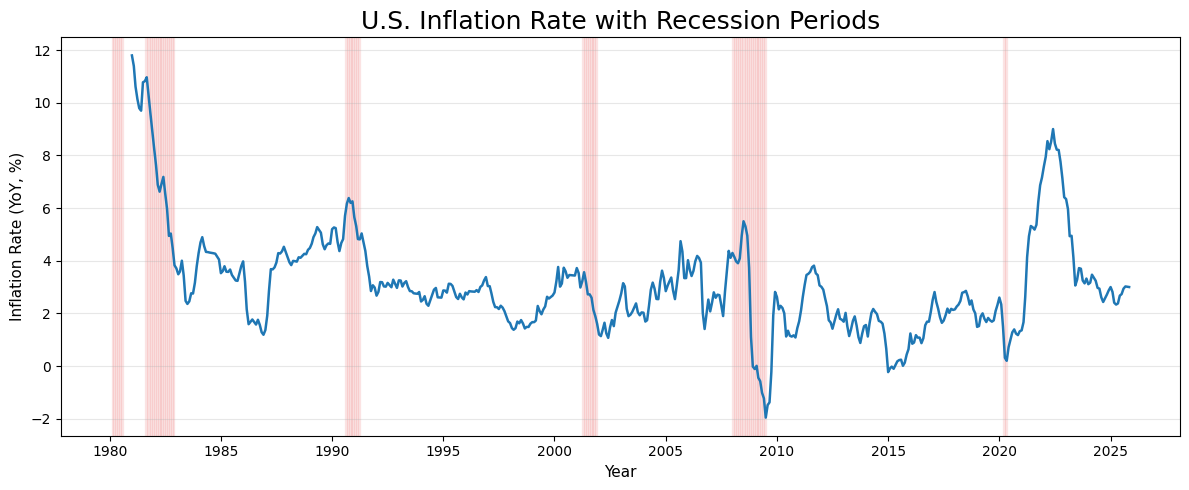

In [139]:
fig, ax = plt.subplots(figsize=(12, 5))

## Inflation line
ax.plot(cpi_plot["Date"], cpi_plot["Inflation_YoY"], linewidth=1.8)

## Recession shading
for i in range(len(recession)):
    if recession.loc[i, 'Recession'] == 1:
        ax.axvspan(recession.loc[i, 'Date'], 
                   recession.loc[i, 'Date'] + pd.offsets.MonthEnd(1),
                   alpha=0.15, color='lightcoral')

ax.set_title("U.S. Inflation Rate with Recession Periods", fontsize=18)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Inflation Rate (YoY, %)", fontsize=11)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

<div class="Excercise 3:"><b>Interpretation</b></div> This figure plots year-over-year CPI inflation with recession periods shaded. The chart demonstrates that inflation behavior is regime-dependent rather than uniformly linked to recessions. The early extreme high inflation rates in the early 1980s corresponded with successive recessions, reflecting the Federal Reserve's aggressive monetary tightening under Chairman Paul Volcker to break entrenched inflation expectations (Goodfriend & King, 2005). In contrast, the 2008–2009 recession aligns with sharp disinflation and temporary deflation, driven by a collapse in aggregate demand following the financial crisis. The post-2020 episode stands apart: instead of occurring during a recession, inflation spiked during the recovery phase, reflecting supply-chain disruptions, fiscal stimulus, and rapid reopening dynamics (Blanchard, 2022).

The key insight is that recession indicators alone do not explain inflation outcomes. Instead, the nature of the underlying shock, such as supply-side versus demand-side, and the credibility of monetary policy play a decisive role. For the investor, this is a distinction with a difference because inflation itself serves as a harbinger of interest rates and discount factors that will influence equity valuations, even in the absence of contraction.

<div class="Excercise 3"><b>Macro Forces in Motion</b></div> 

In [140]:
## GDP growth (quarterly YoY)
gdp_plot = gdp.copy()
gdp_plot["GDP_Growth_YoY"] = gdp_plot["GDP"].pct_change(4) * 100

## Merge datasets
gdp_cpi = gdp_plot.merge(cpi_plot[["Date", "Inflation_YoY"]], on="Date", how="inner")
macro = gdp_cpi.merge(rates, on="Date", how="inner")
macro.head(10)

,Date,GDP,GDP_Growth_YoY,Inflation_YoY,Fed_Funds_Rate
0,1980-01-01,7341.557,NaN,NaN,13.82
1,1980-04-01,7190.289,NaN,NaN,17.61
2,1980-07-01,7181.743,NaN,NaN,9.03
3,1980-10-01,7315.677,NaN,NaN,12.81
4,1981-01-01,7459.022,1.600001,11.794872,19.08
5,1981-04-01,7403.745,2.968671,10.135970,15.72
6,1981-07-01,7492.405,4.325719,10.774818,19.04
7,1981-10-01,7410.768,1.299825,10.271547,15.08
8,1982-01-01,7295.631,-2.190515,8.256881,13.22
9,1982-04-01,7328.912,-1.010745,6.621773,14.94


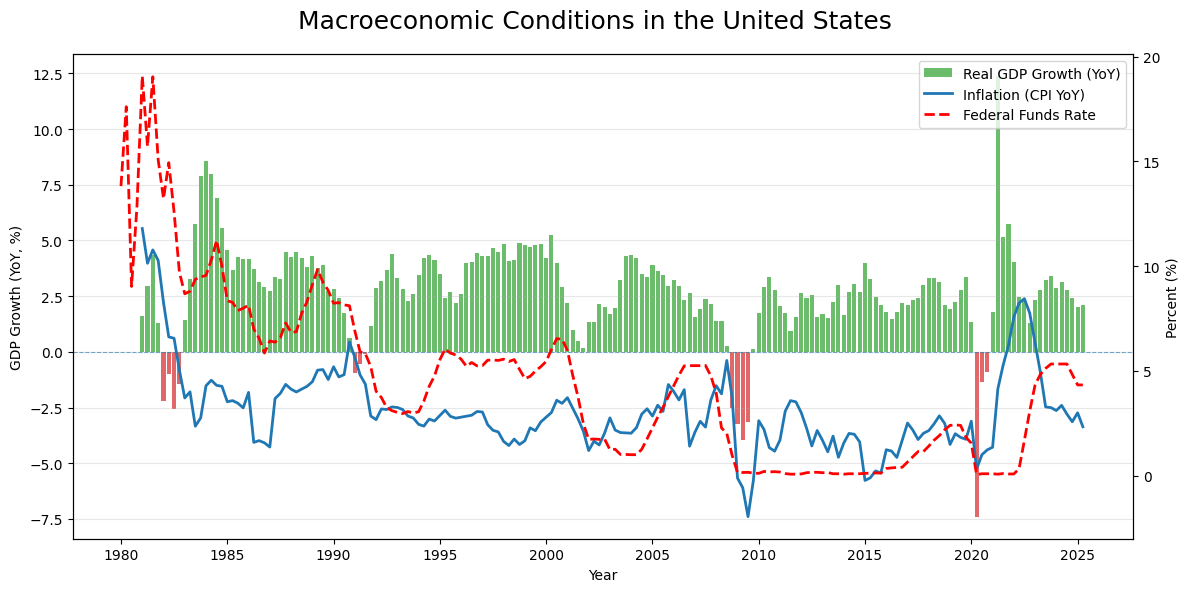

In [141]:
fig, ax1 = plt.subplots(figsize=(12, 6))

## GDP Growth
colors = ["tab:red" if value < 0 else "tab:green" for value in macro["GDP_Growth_YoY"]]

ax1.bar(macro["Date"], macro["GDP_Growth_YoY"], width=70, alpha=0.7, color=colors, label="Real GDP Growth (YoY)")

ax1.axhline(0, linewidth=0.8, linestyle="--", alpha=0.6)
ax1.set_ylabel("GDP Growth (YoY, %)")
ax1.set_xlabel("Year")
ax1.grid(axis="y", alpha=0.3)

## Inflation & Rates
ax2 = ax1.twinx()
ax2.plot(macro["Date"], macro["Inflation_YoY"], linewidth=2, label="Inflation (CPI YoY)")
ax2.plot(macro["Date"], macro["Fed_Funds_Rate"], linewidth=2, linestyle="--", color="red", label="Federal Funds Rate")
ax2.set_ylabel("Percent (%)")

## Title & Legend 
fig.suptitle("Macroeconomic Conditions in the United States", fontsize=18)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper right")
plt.tight_layout()
plt.show()

<div class="Excercise 3:"><b>Interpretation</b></div> This visualization combines real GDP growth, CPI inflation, and the federal funds rate into a single macroeconomic dashboard. The chart highlights a consistent sequencing pattern: monetary policy is responding to inflation and growth conditions rather than leading them. During the Global Financial Crisis, GDP growth turned sharply negative, inflation fell, and the Federal Reserve lowered rates toward the zero lower bound. Conversely, in the post-pandemic period, inflation accelerated during economic recovery; beginning in 2022, one of the fastest tightening cycles in decades is underway.

This pattern aligns with standard monetary policy reaction functions, such as the Taylor rule, which emphasize stabilizing inflation and output gaps (Taylor, 1993). For equity markets, the implication is that macroeconomic conditions are transmitted into asset prices primarily through discount-rate channels. Growth may remain positive, but rising rates can still pressure equity valuations. This mechanism is particularly relevant for high-duration equities, whose valuations are more sensitive to changes in expected discount rates.


<div class="exercise"><b>Exercise 4:</b></div>Create two visualizations which combine information from both data frames

**Apple Stock Data** 

At this stage, macroeconomic indicators are merged with Apple’s stock price data to examine how economy-wide conditions interact with firm-level performance. 

In [142]:
## Import the Apple Stock data 
aapl_path = os.path.join(DATA_DIR, "apple_stock.csv")
if not os.path.exists(aapl_path):
    aapl_path = "apple_stock.csv"
aapl = pd.read_csv(aapl_path)

## Clean the data
aapl.columns = [col.strip().replace(' ','_') for col in aapl.columns]

## Rename column 'Unnamed: 0' into 'Date'
if 'Date' not in aapl.columns:
    aapl = aapl.rename(columns={aapl.columns[0]: 'Date'})
    
aapl["Date"] = pd.to_datetime(aapl["Date"])
aapl = aapl.sort_values("Date").reset_index(drop=True)

## Print the first 5 rows after rename & cleaning
print(aapl.head())

        Date  Adj_Close     Close      High       Low      Open     Volume
0 1980-12-12   0.098834  0.128348  0.128906  0.128348  0.128348  469033600
1 1980-12-15   0.093678  0.121652  0.122210  0.121652  0.122210  175884800
2 1980-12-16   0.086802  0.112723  0.113281  0.112723  0.113281  105728000
3 1980-12-17   0.088951  0.115513  0.116071  0.115513  0.115513   86441600
4 1980-12-18   0.091530  0.118862  0.119420  0.118862  0.118862   73449600


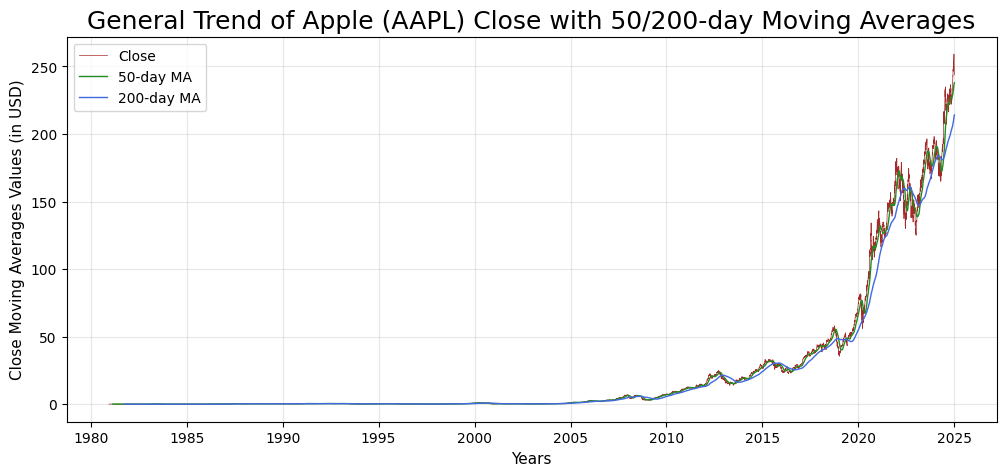

In [143]:
## General Trend of Apple Close Moving Averages within 50/200-day
fig = plt.subplots(figsize=(12,5))

aapl['ma_50'] = aapl['Close'].rolling(50).mean()
aapl['ma_200'] = aapl['Close'].rolling(200).mean()

plt.plot(aapl['Date'], aapl['Close'], label='Close', color='brown', linewidth=0.5)
plt.plot(aapl['Date'], aapl['ma_50'], label='50-day MA', color='forestgreen', linewidth=1)
plt.plot(aapl['Date'], aapl['ma_200'], label='200-day MA', color='royalblue', linewidth=1)
plt.title('General Trend of Apple (AAPL) Close with 50/200-day Moving Averages', fontsize=18)
plt.xlabel('Years', fontsize=11)
plt.ylabel('Close Moving Averages Values (in USD)', fontsize=11)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

<div class="Excercise 4"><b>Apple Stock Price with Recessions and Bear Markets</b></div>

In [144]:
## Monthly Apple (month-end)
aapl_daily_adj = aapl.copy().assign(Date=lambda x: pd.to_datetime(x["Date"])).set_index("Date")["Adj_Close"]
aapl_m = aapl_daily_adj.resample("ME").last().rename("AAPL_Adj_Close").to_frame().reset_index()

## Monthly recession indicator 
recession_daily = recession.copy().assign(Date=lambda x: pd.to_datetime(x["Date"])).set_index("Date")["Recession"]
recession_m = recession_daily.resample("ME").max().rename("Recession").to_frame().reset_index()

## Monthly GDP 
gdp_daily = gdp_plot.copy().assign(Date=lambda x: pd.to_datetime(x["Date"])).set_index("Date")[["GDP_Growth_YoY"]]
gdp_m = gdp_daily.resample("ME").ffill().reset_index()

In [145]:
## Merge Apple Monthly Price with Recession and Gdp
merge_apple_recession = aapl_m.merge(recession_m, on='Date', how='left')
macro_aapl = merge_apple_recession.merge(gdp_m, on='Date', how='left')
macro_aapl = macro_aapl.dropna(subset=["AAPL_Adj_Close"]).sort_values("Date").reset_index(drop=True)
macro_aapl.head(10)

,Date,AAPL_Adj_Close,Recession,GDP_Growth_YoY
0,1980-12-31,0.117313,0,NaN
1,1981-01-31,0.097116,0,1.600001
2,1981-02-28,0.091100,0,1.600001
3,1981-03-31,0.084224,0,1.600001
4,1981-04-30,0.097545,0,2.968671
5,1981-05-31,0.113874,0,2.968671
6,1981-06-30,0.089381,0,2.968671
7,1981-07-31,0.085943,0,4.325719
8,1981-08-31,0.069184,1,4.325719
9,1981-09-30,0.052425,1,4.325719


In [146]:
## Creating Market-Wide Bear Market using SP500
sp500_m = sp500.set_index("Date")["SP500"].resample("ME").last().to_frame().reset_index()

sp500_m["SP500_Peak"] = sp500_m["SP500"].cummax()
sp500_m["SP500_Drawdown"] = sp500_m["SP500"] / sp500_m["SP500_Peak"] - 1
sp500_m["Market_Bear"] = sp500_m["SP500_Drawdown"] <= -0.20
sp500_m.head(10)

,Date,SP500,SP500_Peak,SP500_Drawdown,Market_Bear
0,2015-12-31,2043.94,2043.94,0.000000,False
1,2016-01-31,1940.24,2043.94,-0.050735,False
2,2016-02-29,1932.23,2043.94,-0.054654,False
3,2016-03-31,2059.74,2059.74,0.000000,False
4,2016-04-30,2065.30,2065.30,0.000000,False
5,2016-05-31,2096.96,2096.96,0.000000,False
6,2016-06-30,2098.86,2098.86,0.000000,False
7,2016-07-31,2173.60,2173.60,0.000000,False
8,2016-08-31,2170.95,2173.60,-0.001219,False
9,2016-09-30,2168.27,2173.60,-0.002452,False


In [147]:
## Merge Bear Market with Macro-Apple data
macro_aapl = macro_aapl.merge(sp500_m[["Date", "Market_Bear"]], on="Date", how="left")
macro_aapl["Market_Bear"] = macro_aapl["Market_Bear"].ffill()
macro_aapl.head(10)

,Date,AAPL_Adj_Close,Recession,GDP_Growth_YoY,Market_Bear
0,1980-12-31,0.117313,0,NaN,NaN
1,1981-01-31,0.097116,0,1.600001,NaN
2,1981-02-28,0.091100,0,1.600001,NaN
3,1981-03-31,0.084224,0,1.600001,NaN
4,1981-04-30,0.097545,0,2.968671,NaN
5,1981-05-31,0.113874,0,2.968671,NaN
6,1981-06-30,0.089381,0,2.968671,NaN
7,1981-07-31,0.085943,0,4.325719,NaN
8,1981-08-31,0.069184,1,4.325719,NaN
9,1981-09-30,0.052425,1,4.325719,NaN


In [148]:
## Periods for shading
def contiguous_periods(df, flag_col):
    df = df.sort_values("Date").reset_index(drop=True)
    starts = df.loc[(df[flag_col] == 1) & (df[flag_col].shift(1, fill_value=0) == 0), "Date"]
    ends = df.loc[(df[flag_col] == 1) & (df[flag_col].shift(-1, fill_value=0) == 0), "Date"]
    return list(zip(starts, ends))

recession_periods = contiguous_periods(recession_m, "Recession")
bear_markets = contiguous_periods(macro_aapl, "Market_Bear")

print("Recession periods found:", len(recession_periods))
print("Bear market periods found:", len(bear_markets))

Recession periods found: 6
Bear market periods found: 3


In [149]:
## Filter Date
START_DATE = pd.to_datetime("2000-01-01")
END_DATE = pd.to_datetime("2025-12-31")

macro_aapl_f = macro_aapl[(macro_aapl["Date"] >= START_DATE) & (macro_aapl["Date"] <= END_DATE)].reset_index(drop=True)

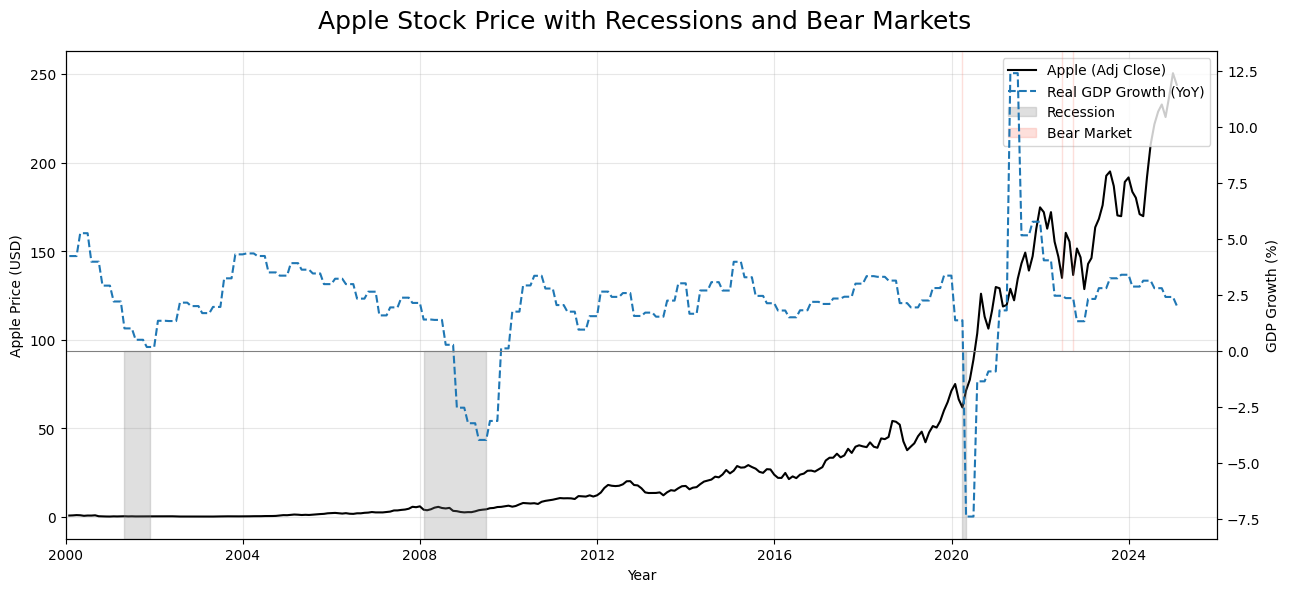

In [150]:
fig, ax_price = plt.subplots(figsize=(13,6))
ax_gdp = ax_price.twinx()

## Apple price line
ax_price.plot(macro_aapl_f["Date"], macro_aapl_f["AAPL_Adj_Close"], 
              linewidth=1.5, 
              color="black", 
              label="Apple (Adj Close)")
ax_price.set_xlabel("Year")
ax_price.set_ylabel("Apple Price (USD)")

## GDP line
ax_gdp.plot(macro_aapl_f["Date"], macro_aapl_f["GDP_Growth_YoY"], 
            linewidth=1.5, 
            linestyle="--", 
            label="Real GDP Growth (YoY)")
ax_gdp.axhline(0, linewidth=0.8, color="gray")
ax_gdp.set_ylabel("GDP Growth (%)")

## Force x-axis window
ax_price.set_xlim(START_DATE, END_DATE)

ymin, ymax = ax_gdp.get_ylim()

## Shade recessions
for i, (start, end) in enumerate(recession_periods):
    ax_gdp.axvspan(start, end,
                   ymin=0, ymax=(0 - ymin) / (ymax - ymin),
                   color="grey", alpha=0.25, 
                   label="Recession" if i == 0 else None)

## Shade bear
for i, (start, end) in enumerate(bear_markets):
    ax_gdp.axvspan(start, end,
                   ymin=(0 - ymin) / (ymax - ymin), ymax=1,
                   color="salmon", alpha=0.25,
                   label="Bear Market" if i == 0 else None)
    
## Title & legend
fig.suptitle("Apple Stock Price with Recessions and Bear Markets", fontsize=18)

lines1, labels1 = ax_price.get_legend_handles_labels()
lines2, labels2 = ax_gdp.get_legend_handles_labels()
ax_price.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

ax_price.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<div class="Excercise 4:"><b>Interpretation</b></div> This visualization links Apple’s equity performance to macroeconomic stress by separately identifying NBER recessions and market-wide bear regimes, where bear markets are defined algorithmically as periods in which the S&P 500 experiences a drawdown of at least 20 percent from its most recent peak. Unlike recessions, which are dated ex post based on real economic activity, this bear-market indicator is price-based and captures investor-driven risk repricing even in the absence of formal economic contraction. The chart reveals a pronounced asymmetry. Recessions consistently coincide with heightened volatility and drawdowns, but they do not dictate Apple’s long-run trajectory. Apple experiences sharp declines during macro shocks, most notably during the 2008–2009 crisis and the 2020 pandemic, but recoveries are rapid and often stronger than the broader economy.

This pattern suggests that macroeconomic stress primarily affects Apple through risk repricing and liquidity conditions rather than through permanent damage to earnings capacity. GDP growth often recovers after equity prices have already rebounded, underscoring that financial markets are forward-looking. For decision-making, the implication is that recession signals are more informative for short-term risk management than for long-term valuation of firms with durable competitive advantages.


<div class="Excercise 4"><b>APPL vs. SP500 Comparison</b></div>

In [151]:
## Convert Apple to monthly (month-end)
aapl_idx = aapl.set_index("Date")["Adj_Close"].resample("ME").last().rename("AAPL").to_frame().reset_index()

## Convert SP500 to monthly (month-end)
spx_idx = sp500.set_index("Date")["SP500"].resample("ME").last().rename("SP500").to_frame().reset_index()

## Merge APPL with SP500
df = aapl_idx.merge(spx_idx, on="Date", how="inner").dropna().reset_index()
df = df[df["Date"] >= pd.to_datetime("2000-01-01")].reset_index(drop=True)

In [152]:
## Compute indexed levels and relative performance 
base_aapl = df["AAPL"].iloc[0]
base_spx  = df["SP500"].iloc[0]

df["AAPL_index"] = 100 * df["AAPL"] / base_aapl
df["SP500_index"] = 100 * df["SP500"] / base_spx

## Cumulative excess return 
df["AAPL_cumret"] = df["AAPL_index"] / 100 - 1
df["SP500_cumret"] = df["SP500_index"] / 100 - 1
df["AAPL_minus_SP500"] = df["AAPL_cumret"] - df["SP500_cumret"]

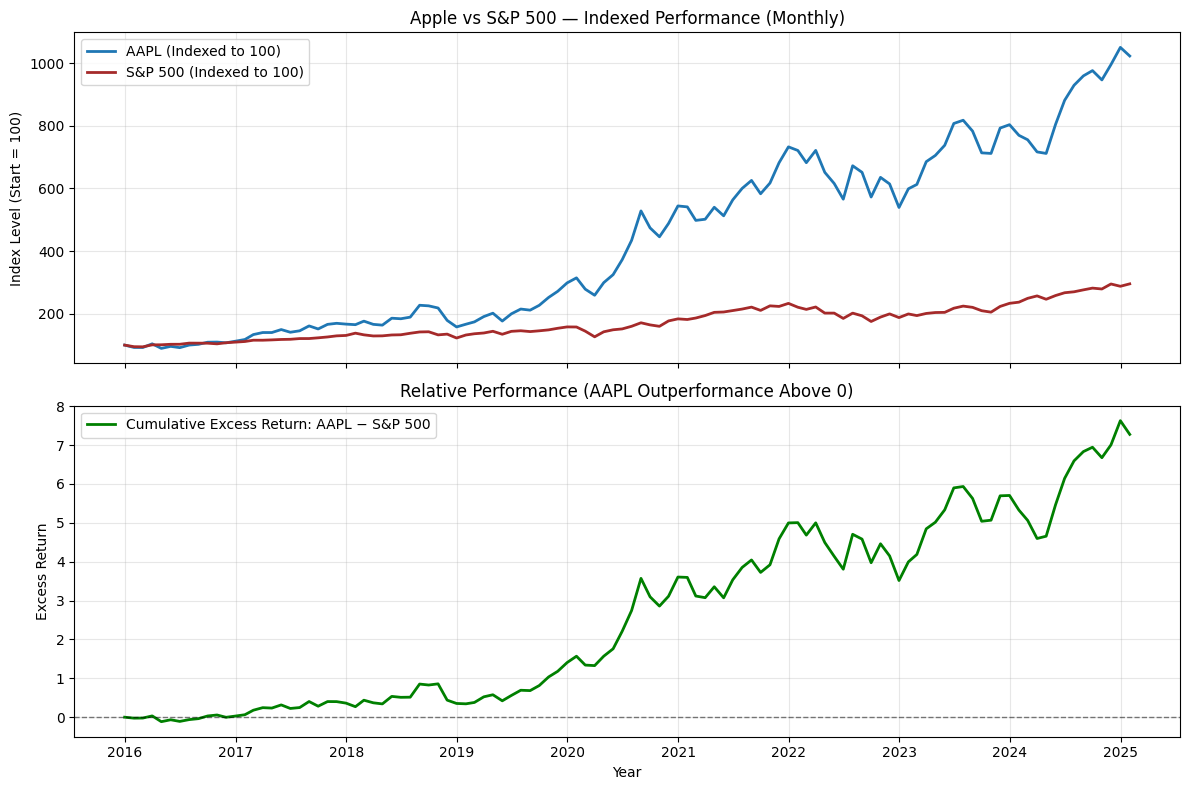

AAPL total return over window: 922.89%
S&P 500 total return over window: 195.53%
AAPL minus S&P 500: 727.36%


In [153]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

## Panel 1: Indexed levels 
ax1.plot(df["Date"], df["AAPL_index"], 
         label="AAPL (Indexed to 100)", 
         linewidth=2)

ax1.plot(df["Date"], df["SP500_index"], 
         label="S&P 500 (Indexed to 100)", 
         linewidth=2, 
         color='brown')

ax1.set_title("Apple vs S&P 500 — Indexed Performance (Monthly)")
ax1.set_ylabel("Index Level (Start = 100)")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper left")

## Panel 2: Relative performance (who is winning)
ax2.plot(df["Date"], df["AAPL_minus_SP500"], 
         linewidth=2,
         color='green',
         label="Cumulative Excess Return: AAPL − S&P 500")

ax2.axhline(0, linestyle="--", linewidth=1, color='black', alpha = 0.5)
ax2.set_title("Relative Performance (AAPL Outperformance Above 0)")
ax2.set_ylabel("Excess Return")
ax2.set_xlabel("Year")
ax2.grid(alpha=0.3)
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

## Summary (under/overperformed?)
aapl_total = df["AAPL_index"].iloc[-1] / 100 - 1
spx_total  = df["SP500_index"].iloc[-1] / 100 - 1

print(f"AAPL total return over window: {aapl_total:.2%}")
print(f"S&P 500 total return over window: {spx_total:.2%}")
print(f"AAPL minus S&P 500: {(aapl_total - spx_total):.2%}")

<div class="Excercise 4:"><b>Interpretation</b></div> 
The final visualization compares Apple’s performance to the S&P 500 using indexed levels and cumulative excess returns. Indexing isolates relative wealth creation rather than absolute price movements. The results show persistent and substantial outperformance by Apple over the sample period. The cumulative excess return remains positive and increases over time, indicating that Apple’s returns cannot be explained solely by market beta.

This sustained outperformance reflects firm-specific factors such as innovation, ecosystem lock-in, pricing power, and scale economies. However, the analysis also highlights a forward-looking constraint: persistent outperformance embeds high expectations into valuations. As expectations rise, future returns become more sensitive to macroeconomic conditions that affect discount rates and earnings surprises. Thus, while Apple’s historical performance demonstrates strong fundamentals, macroeconomic regimes still matter for timing and risk assessment.


<div class="exercise"><b>Exercise 5:</b></div> Outline how the new data either make you reconsider your hypothesis from the first project or reinforce your conclusions. What new additional questions can you ask? What would the next steps be to answer those questions?

Combining this with the macroeconomic data reinforces my finding from Project 1: it is firm-specific fundamentals that drive Apple's long-run performance, while the impact of macroeconomic regimes is primarily reflected in short-term volatility and valuation pressure. Among these, inflation and monetary policy prove to be more immediate channels than recession indicators.         

Future research, incorporating additional data sources such as news sentiment, earnings call tone, or measures of market uncertainty, can help capture non-macroeconomic drivers of price movements. A natural next step would be to build a predictive model that combines macro variables with firm-level indicators and sentiment measures to forecast returns or volatility regimes. Such a model could improve decision-making by distinguishing between macro-driven drawdowns and changes driven by shifts in firm fundamentals.
